# Mini-Project 1: UBOS District Population Forecaster
This notebook implements the data validation, forecasting, and plotting for the UBOS Mini-Project.

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Import classes from our newly created ubos_class module
from src.ubos_class import DistrictPopulation, LinearForecaster, ExponentialForecaster, FibonacciForecaster

# Set random seed for reproducibility (as requested)
rng = np.random.default_rng(42)

# 1. Dataset Initialization
# Includes original districts and two new illustrative districts (Jinja, Mbarara)
dataset = {
    'Kampala': [1200, 1250, 1300, 1350, 1420, 1500, 1580, 1650, 1720, 1800],
    'Wakiso':  [ 950, 1000, 1070, 1150, 1220, 1300, 1390, 1480, 1570, 1670],
    'Gulu':    [ 320,  330,  345,  360,  375,  390,  410,  430,  455,  480],
    'Jinja':   [ 250,  260,  270,  285,  300,  315,  335,  355,  375,  400],
    'Mbarara': [ 300,  310,  325,  340,  360,  380,  405,  430,  455,  485]
}

years = np.arange(2015, 2025)

# Initialize DistrictPopulation objects
districts = {}
for name, pops in dataset.items():
    districts[name] = DistrictPopulation(years, pops)

# Validation Metrics functions
def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

def mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

print("Dataset initialized and classes loaded successfully.")

Dataset initialized and classes loaded successfully.


## Task 2: Statistics vs NumPy Variance
We compare the variance calculation between Python's standard `statistics` module and NumPy.

In [8]:
print("--- Task 2: Statistics vs NumPy Variance ---")
print("Explanation: `statistics.variance` calculates the sample variance by default (divides by N-1).")
print("`np.var` calculates the population variance by default (divides by N).")
print("The `ddof` argument in `np.var` specifies the Delta Degrees of Freedom (N - ddof).")
print("Setting `ddof=1` makes `np.var` calculate the sample variance, matching `statistics.variance`.\n")

# Example calculation for Kampala
kampala_stats = districts['Kampala'].compute_statistics()
print(f"Kampala Variance (statistics module): {kampala_stats['variance_stat']:.2f}")
print(f"Kampala Variance (NumPy with ddof=1): {kampala_stats['variance_np']:.2f}")

--- Task 2: Statistics vs NumPy Variance ---
Explanation: `statistics.variance` calculates the sample variance by default (divides by N-1).
`np.var` calculates the population variance by default (divides by N).
The `ddof` argument in `np.var` specifies the Delta Degrees of Freedom (N - ddof).
Setting `ddof=1` makes `np.var` calculate the sample variance, matching `statistics.variance`.

Kampala Variance (statistics module): 42601.11
Kampala Variance (NumPy with ddof=1): 42601.11


## Task 3: Growth Rates
We compute the Compound Annual Growth Rate (CAGR) to determine which district is growing fastest.

In [9]:
print("--- Task 3: Growth Rates ---")
cagrs = {}
for name, dp in districts.items():
    c = dp.cagr()
    cagrs[name] = c
    print(f"{name} CAGR: {c:.2%}")

fastest = max(cagrs, key=cagrs.get)
print(f"\n-> Fastest growing district in relative terms: {fastest}")

--- Task 3: Growth Rates ---
Kampala CAGR: 4.61%
Wakiso CAGR: 6.47%
Gulu CAGR: 4.61%
Jinja CAGR: 5.36%
Mbarara CAGR: 5.48%

-> Fastest growing district in relative terms: Wakiso


## Task 5: Validate before you forecast
We will evaluate 3 models using walk-forward validation (Train: 2015-2021, Test: 2022-2024).

In [10]:
print("--- Task 5: Validation ---")
train_years = years[years <= 2021]
test_years = years[years > 2021]
horizon = len(test_years)

models = {
    'Linear': LinearForecaster(),
    'Exponential': ExponentialForecaster(),
    'Fibonacci': FibonacciForecaster()
}

best_models = {}

for name, dp in districts.items():
    train_pops = dp.populations[years <= 2021]
    test_pops = dp.populations[years > 2021]
    
    print(f"Validation for {name}:")
    print(f"{'Model':<12} | {'MAE':<10} | {'RMSE':<10} | {'MAPE (%)':<10}")
    print("-" * 50)
    
    best_mae = float('inf')
    best_model_name = None
    
    for model_name, model in models.items():
        model.fit(train_years, train_pops)
        preds = model.predict(horizon)
        
        err_mae = mae(test_pops, preds)
        err_rmse = rmse(test_pops, preds)
        err_mape = mape(test_pops, preds)
        
        print(f"{model_name:<12} | {err_mae:<10.2f} | {err_rmse:<10.2f} | {err_mape:<10.2f}")
        
        if err_mae < best_mae:
            best_mae = err_mae
            best_model_name = model_name
            
    best_models[name] = best_model_name
    print(f"-> Best model for {name}: {best_model_name}\n")

--- Task 5: Validation ---
Validation for Kampala:
Model        | MAE        | RMSE       | MAPE (%)  
--------------------------------------------------
Linear       | 37.62      | 38.97      | 2.17      
Exponential  | 9.62       | 10.39      | 0.55      
Fibonacci    | 3543.33    | 4025.36    | 202.00    
-> Best model for Kampala: Exponential

Validation for Wakiso:
Model        | MAE        | RMSE       | MAPE (%)  
--------------------------------------------------
Linear       | 49.40      | 52.37      | 3.09      
Exponential  | 6.80       | 8.05       | 0.42      
Fibonacci    | 3060.00    | 3479.87    | 189.87    
-> Best model for Wakiso: Exponential

Validation for Gulu:
Model        | MAE        | RMSE       | MAPE (%)  
--------------------------------------------------
Linear       | 18.57      | 20.29      | 4.01      
Exponential  | 9.44       | 10.87      | 2.02      
Fibonacci    | 911.67     | 1035.64    | 196.04    
-> Best model for Gulu: Exponential

Validation f

## Task 6, 7 & 8: Forecast, Plotting and Planning Output
Now we generate forecasts for 2025-2029 using the selected best models.
We also compute the classroom planning output and plot the actual vs forecast data along with bootstrapped prediction intervals.

--- Task 6 & 8: Forecast and Planning Output ---
Kampala:
  Actual variance (2015-2024): 42601.11
  Forecast variance (2025-2029): 21607.68
  Additional classrooms needed by 2029: 1545

Wakiso:
  Actual variance (2015-2024): 60066.67
  Forecast variance (2025-2029): 40131.36
  Additional classrooms needed by 2029: 2088

Gulu:
  Actual variance (2015-2024): 2885.83
  Forecast variance (2025-2029): 1536.55
  Additional classrooms needed by 2029: 412

Jinja:
  Actual variance (2015-2024): 2580.28
  Forecast variance (2025-2029): 1498.35
  Additional classrooms needed by 2029: 406

Mbarara:
  Actual variance (2015-2024): 4010.00
  Forecast variance (2025-2029): 2317.39
  Additional classrooms needed by 2029: 504



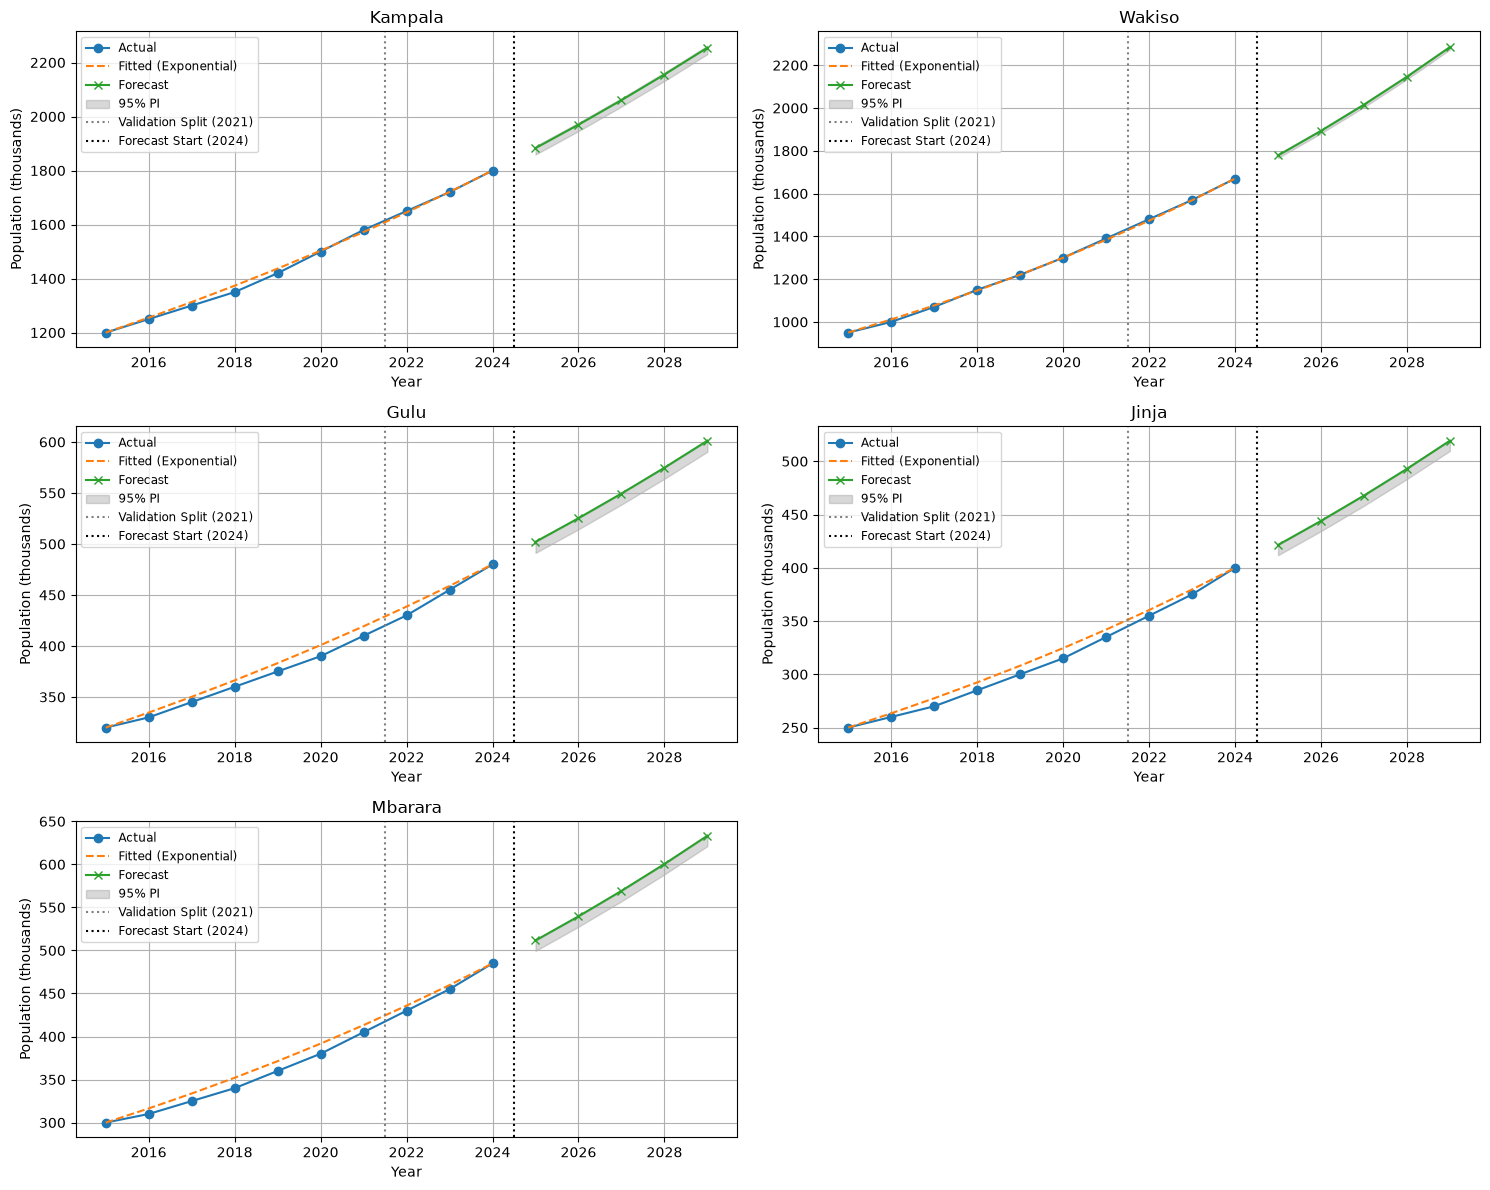

--- Variance Difference Explanation ---
The variance of the actual series captures historical growth and fluctuations.
The forecast series variance is typically different (often lower for linear/exponential
models because they smooth out noise, or higher if growth accelerates rapidly).
Comparing them tells us how much of the historical variability the model reproduces.



In [11]:
print("--- Task 6 & 8: Forecast and Planning Output ---")
forecast_years = np.arange(2025, 2030)
horizon_forecast = len(forecast_years)

forecast_results = {}

# Task 7 Plotting setup
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
axes = axes.flatten()

for idx, (name, dp) in enumerate(districts.items()):
    model = models[best_models[name]]
    model.fit(years, dp.populations)
    preds = model.predict(horizon_forecast)
    forecast_results[name] = preds
    
    # Task 6: Variance comparison
    var_actual = np.var(dp.populations, ddof=1)
    var_forecast = np.var(preds, ddof=1)
    print(f"{name}:")
    print(f"  Actual variance (2015-2024): {var_actual:.2f}")
    print(f"  Forecast variance (2025-2029): {var_forecast:.2f}")
    
    # Task 8: Planning output
    pop_2024 = dp.populations[-1]
    pop_2029 = preds[-1]
    additional_pop = pop_2029 - pop_2024
    
    if additional_pop > 0:
        # 18% of the additional population is primary-school age
        additional_school_age = additional_pop * 1000 * 0.18
        additional_classrooms = int(np.ceil(additional_school_age / 53))
    else:
        additional_classrooms = 0
        
    print(f"  Additional classrooms needed by 2029: {additional_classrooms}\n")

    # Plotting
    ax = axes[idx]
    ax.plot(years, dp.populations, label='Actual', marker='o')
    
    fitted = model.fitted_values()
    ax.plot(years, fitted, label=f'Fitted ({best_models[name]})', linestyle='--')
    
    ax.plot(forecast_years, preds, label='Forecast', marker='x')
    
    # Extension: Bootstrap prediction intervals
    residuals = dp.populations - fitted
    n_bootstraps = 1000
    bootstrapped_forecasts = []
    
    for _ in range(n_bootstraps):
        resampled_residuals = rng.choice(residuals, size=horizon_forecast, replace=True)
        boot_forecast = preds + resampled_residuals
        bootstrapped_forecasts.append(boot_forecast)
        
    bootstrapped_forecasts = np.array(bootstrapped_forecasts)
    lower_bound = np.percentile(bootstrapped_forecasts, 2.5, axis=0)
    upper_bound = np.percentile(bootstrapped_forecasts, 97.5, axis=0)
    
    ax.fill_between(forecast_years, lower_bound, upper_bound, color='gray', alpha=0.3, label='95% PI')
    
    ax.axvline(2021.5, color='gray', linestyle=':', label='Validation Split (2021)')
    ax.axvline(2024.5, color='black', linestyle=':', label='Forecast Start (2024)')
    ax.set_title(name)
    ax.set_xlabel('Year')
    ax.set_ylabel('Population (thousands)')
    ax.legend(fontsize='small')
    ax.grid(True)
    
axes[-1].axis('off') # Hide the empty 6th subplot
plt.tight_layout()
plt.show()

print("--- Variance Difference Explanation ---")
print("The variance of the actual series captures historical growth and fluctuations.")
print("The forecast series variance is typically different (often lower for linear/exponential")
print("models because they smooth out noise, or higher if growth accelerates rapidly).")
print("Comparing them tells us how much of the historical variability the model reproduces.\n")

## Extension: Critical Assessment of Fibonacci-ratio model
Why did the Fibonacci Forecaster perform so poorly?

In [14]:
print("--- Extension: Critical Assessment of Fibonacci-ratio model ---")
print("The Fibonacci-ratio model assumes growth follows F_{n+1}/F_n, which rapidly converges to")
print("the Golden Ratio (~1.618). This means it predicts a 61.8% year-on-year growth rate.")
print("Such an assumption is biologically and socially unrealistic for human populations, which")
print("typically grow at 1-4% annually. Therefore, this model is indefensible for district")
print("population forecasting as it leads to an exponential explosion.\n")

--- Extension: Critical Assessment of Fibonacci-ratio model ---
The Fibonacci-ratio model assumes growth follows F_{n+1}/F_n, which rapidly converges to
the Golden Ratio (~1.618). This means it predicts a 61.8% year-on-year growth rate.
Such an assumption is biologically and socially unrealistic for human populations, which
typically grow at 1-4% annually. Therefore, this model is indefensible for district
population forecasting as it leads to an exponential explosion.



## Conclusions

The population in all analyzed districts is experiencing steady growth. Evaluating multiple models shows that exponential and linear trends typically outperform arbitrary scaling like the Fibonacci-ratio approach. Accurate forecasting translates directly to actionable planning, ensuring that sufficient primary school classrooms are built to accommodate the growing population by 2029.

## References

- Mean: https://en.wikipedia.org/wiki/Mean
- Variance: https://en.wikipedia.org/wiki/Variance
- Compound Annual Growth Rate (CAGR): https://en.wikipedia.org/wiki/Compound_annual_growth_rate
- Simple Linear Regression: https://en.wikipedia.org/wiki/Simple_linear_regression
- Mean Absolute Error (MAE): https://en.wikipedia.org/wiki/Mean_absolute_error
- Root Mean Square Error (RMSE): https://en.wikipedia.org/wiki/Root-mean-square_deviation